# Imports

In [12]:
from langgraph.graph import StateGraph, START, END
from langchain_openai import ChatOpenAI
from typing import TypedDict
from dotenv import load_dotenv

# Loading env variables

In [13]:
load_dotenv()

True

# Define LLM

In [14]:
model = ChatOpenAI(model="gpt-4o-mini") 

# Define State

In [15]:
class BlogState(TypedDict):

    title: str
    outline: str
    content: str

# Creating Nodes

In [16]:
def create_outline(state: BlogState) -> BlogState:

    # fetch title
    title = state['title']

    # call llm gen outline
    prompt = f'Generate a detailed outline for a blog on the topic - {title}'
    outline = model.invoke(prompt).content

    # update state
    state['outline'] = outline

    return state

In [17]:
def create_blog(state: BlogState) -> BlogState:

    title = state['title']
    outline = state['outline']

    prompt = f'Write a detailed blog on the title - {title} using the follwing outline \n {outline}'

    content = model.invoke(prompt).content

    state['content'] = content

    return state

# Define and Compile Graph

In [18]:
graph = StateGraph(BlogState)

# nodes
graph.add_node('create_outline', create_outline)
graph.add_node('create_blog', create_blog)

# edges
graph.add_edge(START, 'create_outline')
graph.add_edge('create_outline', 'create_blog')
graph.add_edge('create_blog', END)

workflow = graph.compile()


# Execute the Graph

In [19]:
intial_state = {'title': 'Rise of AI in India'}

final_state = workflow.invoke(intial_state)

print(final_state)

{'title': 'Rise of AI in India', 'outline': "## Detailed Outline for Blog: The Rise of AI in India\n\n### Introduction\n- Brief overview of Artificial Intelligence (AI) and its significance in today’s world.\n- Introduction to the context of India as a rising tech hub.\n- Purpose of the blog: To explore the growth and impact of AI in India.\n\n---\n\n### 1. Historical Context of AI Development in India\n- **Early Initiatives**\n  - Overview of AI research and development in India in the 1980s through 2000s.\n  - Key universities and research institutions involved in early AI projects.\n  - Initial government policies and investments in technology.\n\n- **Technological Landscape Pre-2010**\n  - Overview of the tech ecosystem before the AI boom.\n  - Role of IT services and software development in shaping the future.\n\n---\n\n### 2. Current State of AI in India\n- **Emergence and Growth of AI Startups**\n  - Statistics on AI startup growth in recent years.\n  - Notable AI startups (e.g.

In [20]:
print(final_state['outline'])

## Detailed Outline for Blog: The Rise of AI in India

### Introduction
- Brief overview of Artificial Intelligence (AI) and its significance in today’s world.
- Introduction to the context of India as a rising tech hub.
- Purpose of the blog: To explore the growth and impact of AI in India.

---

### 1. Historical Context of AI Development in India
- **Early Initiatives**
  - Overview of AI research and development in India in the 1980s through 2000s.
  - Key universities and research institutions involved in early AI projects.
  - Initial government policies and investments in technology.

- **Technological Landscape Pre-2010**
  - Overview of the tech ecosystem before the AI boom.
  - Role of IT services and software development in shaping the future.

---

### 2. Current State of AI in India
- **Emergence and Growth of AI Startups**
  - Statistics on AI startup growth in recent years.
  - Notable AI startups (e.g., Niramai, Haptik, Fractal Analytics).
  - Case studies of successful

In [21]:
print(final_state['content'])

# The Rise of AI in India

## Introduction
Artificial Intelligence (AI) has emerged as a revolutionary force in numerous sectors globally, transforming how we interact with technology and make decisions. In India, a nation often dubbed as a rising tech hub, AI is rapidly reshaping industries, enhancing productivity, and providing innovative solutions to longstanding challenges. This blog aims to delve deep into the growth trajectory and multifaceted impact of AI in India, exploring its historical context, current state, key sectors influenced, challenges faced, and future prospects.

---

## 1. Historical Context of AI Development in India

### Early Initiatives
AI research in India dates back to the 1980s, a period marked by initial forays into machine learning and natural language processing. Notable institutions such as the Indian Institute of Technology (IIT) and the Indian Statistical Institute began experimenting with AI concepts, laying the groundwork for future advancements. Th

# Visualize Graph (Optional)

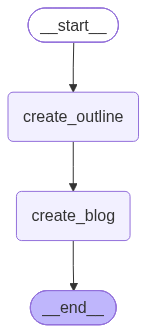

In [22]:
from IPython.display import Image
Image(workflow.get_graph().draw_mermaid_png())